# 5. Image Segmentation

Practice for week 5: Otsu's threshold from scratch (and when it is not unique), multi-level Otsu for a
three-class image, and the Hough transform for lines and for circles of known radius.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)
yy, xx = np.mgrid[:128, :128]

## 5.1 Otsu's method

Simple thresholding needs a hand-picked value. Otsu tries every threshold and picks the one that maximizes
the between-class variance `σ_B²(t) = (μ_T ω(t) − μ(t))² / (ω(t)(1 − ω(t)))`, computed from the histogram.

Otsu threshold 0.492, pixel accuracy 0.974


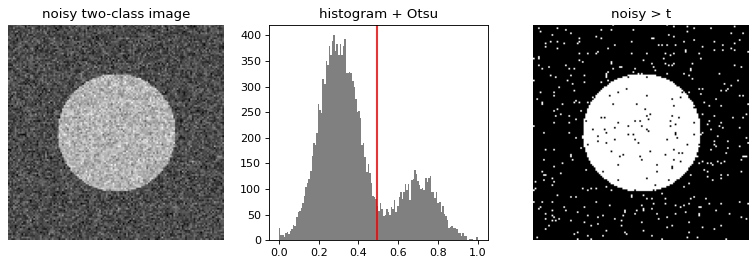

clean image: thresholds reaching the maximum: 103 -> every t between the two levels is optimal, so the threshold is not unique


In [2]:
def between_class_variance(u, bins=256):
    h, _ = np.histogram(u, bins, (0, 1)); p = h / h.sum()
    levels = (np.arange(bins) + 0.5) / bins
    w0, mu = np.cumsum(p), np.cumsum(p * levels)
    return (mu[-1] * w0 - mu) ** 2 / (w0 * (1 - w0) + 1e-12)

clean = np.where((xx - 64) ** 2 + (yy - 64) ** 2 < 35 ** 2, 0.7, 0.3)
noisy = (clean + rng.normal(0, 0.1, clean.shape)).clip(0, 1)
sb = between_class_variance(noisy)
t = (np.argmax(sb) + 1) / 256
print(f"Otsu threshold {t:.3f}, pixel accuracy {((noisy > t) == (clean > 0.5)).mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(noisy, cmap="gray"); axes[0].set_title("noisy two-class image")
axes[1].hist(noisy.ravel(), 128, color="gray"); axes[1].axvline(t, color="r"); axes[1].set_title("histogram + Otsu")
axes[2].imshow(noisy > t, cmap="gray"); axes[2].set_title("noisy > t")
axes[0].axis("off"); axes[2].axis("off"); plt.show()

sb_clean = between_class_variance(clean)
print("clean image: thresholds reaching the maximum:", int(np.isclose(sb_clean, sb_clean.max()).sum()),
      "-> every t between the two levels is optimal, so the threshold is not unique")

## 5.2 Multi-level Otsu

With three classes the histogram is trimodal and one threshold is not enough. Search over pairs of
thresholds and maximize `Σ ω_k (μ_k − μ_T)²`.

two Otsu thresholds: (0.328125, 0.671875)


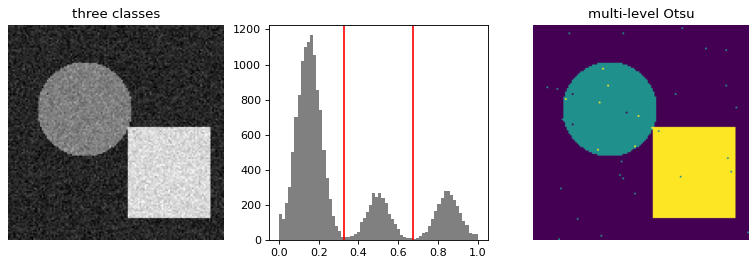

In [3]:
three = np.full((128, 128), 0.15)
three[(xx - 45) ** 2 + (yy - 50) ** 2 < 28 ** 2] = 0.5
three[(xx > 70) & (xx < 120) & (yy > 60) & (yy < 115)] = 0.85
three = (three + rng.normal(0, 0.06, three.shape)).clip(0, 1)

h, _ = np.histogram(three, 64, (0, 1)); p = h / h.sum(); lv = (np.arange(64) + 0.5) / 64; mt = (p * lv).sum()
best, best_ts = -1, None
for t1 in range(1, 63):
    for t2 in range(t1 + 1, 64):
        s = 0
        for lo, hi in [(0, t1), (t1, t2), (t2, 64)]:
            w = p[lo:hi].sum()
            if w > 0: s += w * ((p[lo:hi] * lv[lo:hi]).sum() / w - mt) ** 2
        if s > best: best, best_ts = s, (t1 / 64, t2 / 64)
print("two Otsu thresholds:", best_ts)
labels = np.digitize(three, best_ts)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(three, cmap="gray"); axes[0].axis("off"); axes[0].set_title("three classes")
axes[1].hist(three.ravel(), 64, color="gray"); [axes[1].axvline(v, color="r") for v in best_ts]
axes[2].imshow(labels, cmap="viridis"); axes[2].axis("off"); axes[2].set_title("multi-level Otsu")
plt.show()

## 5.3 Hough transform for lines

Every edge point `(x, y)` votes for all lines through it: `ρ = x cos θ + y sin θ`. Points on the same line
vote for the same `(ρ, θ)` cell, so lines appear as peaks in the accumulator, even with gaps and clutter.
A line has two parameters, so the accumulator is 2D.

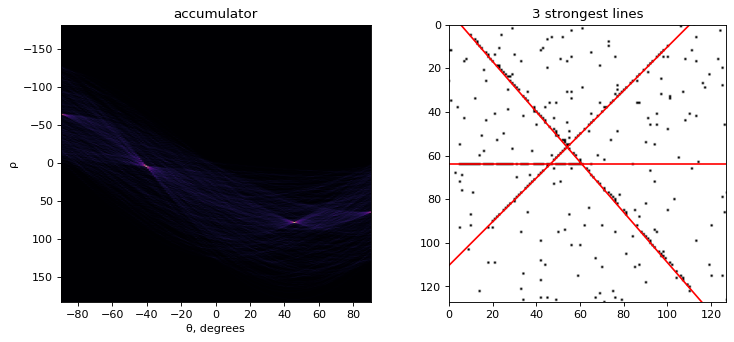

In [4]:
def segment(p, q, n=120):
    t = np.linspace(0, 1, n)
    return np.round(p[0] + t * (q[0] - p[0])).astype(int), np.round(p[1] + t * (q[1] - p[1])).astype(int)

edges = np.zeros((128, 128), bool)
for p, q in [((10, 5), (110, 120)), ((100, 10), (20, 90)), ((5, 64), (60, 64))]:
    xs, ys = segment(p, q); keep = rng.random(len(xs)) > 0.3          # 30% of the line missing
    edges[ys[keep], xs[keep]] = True
edges[rng.integers(0, 128, 200), rng.integers(0, 128, 200)] = True   # clutter

thetas = np.deg2rad(np.arange(-90, 90))
diag = int(np.ceil(np.hypot(128, 128)))
ys, xs = np.nonzero(edges)
rho = np.round(xs[:, None] * np.cos(thetas) + ys[:, None] * np.sin(thetas)).astype(int) + diag
acc = np.zeros((2 * diag + 1, len(thetas)), int)
np.add.at(acc, (rho, np.broadcast_to(np.arange(len(thetas)), rho.shape)), 1)

peaks, A = [], acc.copy()
for _ in range(3):
    r_i, t_i = np.unravel_index(A.argmax(), A.shape); peaks.append((r_i - diag, thetas[t_i]))
    A[max(r_i - 8, 0):r_i + 9, max(t_i - 8, 0):t_i + 9] = 0

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(acc, aspect="auto", cmap="magma", extent=[-90, 90, diag, -diag]); axes[0].set_xlabel("θ, degrees"); axes[0].set_ylabel("ρ")
axes[0].set_title("accumulator")
axes[1].imshow(edges, cmap="gray_r")
x = np.arange(128)
for r_, th in peaks:
    if abs(np.sin(th)) > 1e-6: axes[1].plot(x, (r_ - x * np.cos(th)) / np.sin(th), "r", lw=1.5)
    else: axes[1].axvline(r_ / np.cos(th), color="r", lw=1.5)
axes[1].set_xlim(0, 127); axes[1].set_ylim(127, 0); axes[1].set_title("3 strongest lines")
plt.show()

## 5.4 Hough transform for circles of known radius

A circle has three parameters `(a, b, r)`. If `r` is known, each edge point votes for all centres at
distance `r` from it, and the accumulator is 2D again. A circle that is half hidden still gets a clear peak.
A circle of a different radius gets no peak.

detected centres (x, y, votes): [(35, 35, 168), (60, 95, 133), (90, 40, 97)]


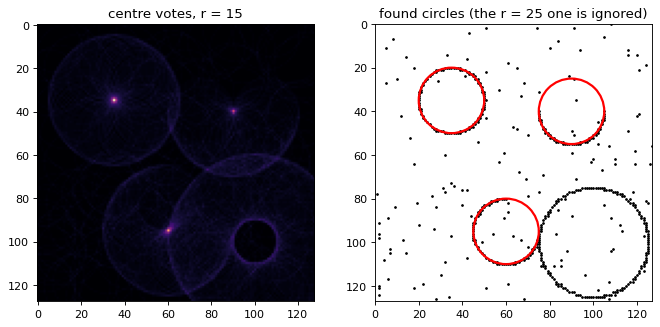

In [5]:
r0 = 15
pts = []
for (cx, cy, r, arc) in [(35, 35, r0, 2 * np.pi), (90, 40, r0, np.pi), (60, 95, r0, 1.5 * np.pi), (100, 100, 25, 2 * np.pi)]:
    a = np.linspace(0, arc, 200)
    pts.append(np.c_[cx + r * np.cos(a), cy + r * np.sin(a)])
pts = np.round(np.vstack(pts + [rng.uniform(0, 128, (150, 2))])).astype(int).clip(0, 127)
pts = np.unique(pts, axis=0)

acc = np.zeros((128, 128), int)
a = np.deg2rad(np.arange(0, 360, 2))
cx = np.round(pts[:, :1] - r0 * np.cos(a)).astype(int); cy = np.round(pts[:, 1:] - r0 * np.sin(a)).astype(int)
ok = (cx >= 0) & (cx < 128) & (cy >= 0) & (cy < 128)
np.add.at(acc, (cy[ok], cx[ok]), 1)
found, A = [], acc.copy()
for _ in range(3):
    y0, x0 = np.unravel_index(A.argmax(), A.shape); found.append((int(x0), int(y0), int(A[y0, x0]))); A[y0 - 6:y0 + 7, x0 - 6:x0 + 7] = 0
print("detected centres (x, y, votes):", found)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(acc, cmap="magma"); axes[0].set_title(f"centre votes, r = {r0}")
axes[1].scatter(pts[:, 0], pts[:, 1], s=2, c="k"); axes[1].set_xlim(0, 127); axes[1].set_ylim(127, 0); axes[1].set_aspect("equal")
for x0, y0, _ in found:
    axes[1].add_patch(plt.Circle((x0, y0), r0, fill=False, color="r", lw=2))
axes[1].set_title("found circles (the r = 25 one is ignored)"); plt.show()